## Week 2 Lab: Input Representation

Requirements:
```
pip install tiktoken tokenizers gensim sentence-transformers matplotlib
```

## Part 1: Exploring Tokenization with tiktoken

We'll use OpenAI's `tiktoken` library to see how the GPT-4 tokenizer (cl100k_base) handles different kinds of text.


In [ ]:
import tiktoken

enc = tiktoken.get_encoding("cl100k_base")  # GPT-4 / GPT-3.5 tokenizer

def show_tokens(text: str, enc=enc):
    token_ids = enc.encode(text)
    tokens    = [enc.decode([t]) for t in token_ids]
    print(f"Text   : {text!r}")
    print(f"Tokens : {tokens}")
    print(f"IDs    : {token_ids}")
    print(f"Count  : {len(token_ids)}\n")


### 1a Basic examples

In [ ]:
show_tokens("Hello, world!")
show_tokens("unbelievable")
show_tokens("ChatGPT")


Text   : 'Hello, world!'
Tokens : ['Hello', ',', ' world', '!']
IDs    : [9906, 11, 1917, 0]
Count  : 4

Text   : 'unbelievable'
Tokens : ['un', 'belie', 'vable']
IDs    : [359, 32898, 24694]
Count  : 3

Text   : 'ChatGPT'
Tokens : ['Chat', 'G', 'PT']
IDs    : [16047, 38, 2898]
Count  : 3



### 1b Numbers

Notice how tokenization is inconsistent across integers

In [ ]:
for n in ["0", "1", "42", "100", "1000", "12345", "1000000"]:
    ids = enc.encode(n)
    print(f"{n:>10}  ->  {len(ids)} token(s)  {ids}")


         0  ->  1 token(s)  [15]
         1  ->  1 token(s)  [16]
        42  ->  1 token(s)  [2983]
       100  ->  1 token(s)  [1041]
      1000  ->  2 token(s)  [1041, 15]
     12345  ->  2 token(s)  [4513, 1774]
   1000000  ->  3 token(s)  [1041, 931, 15]


### 1c Arithmetic tokens

Same token count, very different meaning

In [ ]:
show_tokens("9 + 5 = 14")
show_tokens("9 + 5 = 23")   # wrong answer, same structure: model must know math statistically


Text   : '9 + 5 = 14'
Tokens : ['9', ' +', ' ', '5', ' =', ' ', '14']
IDs    : [24, 489, 220, 20, 284, 220, 975]
Count  : 7

Text   : '9 + 5 = 23'
Tokens : ['9', ' +', ' ', '5', ' =', ' ', '23']
IDs    : [24, 489, 220, 20, 284, 220, 1419]
Count  : 7



### 1d Multilingual inequality — same sentence, wildly different token counts

In [ ]:
sentences = {
    "English":  "The weather is beautiful today and I am very happy.",
    "French":   "Le temps est magnifique aujourd'hui et je suis très heureux.",
    "German":   "Das Wetter ist heute wunderschön und ich bin sehr glücklich.",
    "Arabic":   "الطقس جميل اليوم وأنا سعيد جداً.",
    "Thai":     "วันนี้อากาศสวยงามมากและฉันมีความสุขมาก",
    "Chinese":  "今天天气很好，我非常高兴。",
}

print(f"{'Language':<12} {'Tokens':>8}  {'Tokenized'}")
print("-" * 60)
for lang, sent in sentences.items():
    ids    = enc.encode(sent)
    tokens = [enc.decode([t]) for t in ids]
    print(f"{lang:<12} {len(ids):>8}  {tokens}")


Language       Tokens  Tokenized
------------------------------------------------------------
English            11  ['The', ' weather', ' is', ' beautiful', ' today', ' and', ' I', ' am', ' very', ' happy', '.']
French             14  ['Le', ' temps', ' est', ' magn', 'ifique', ' aujourd', "'hui", ' et', ' je', ' suis', ' très', ' heure', 'ux', '.']
German             17  ['Das', ' W', 'etter', ' ist', ' heute', ' w', 'unders', 'ch', 'ön', ' und', ' ich', ' bin', ' sehr', ' gl', 'ück', 'lich', '.']
Arabic             25  ['ال', 'ط', 'ق', 'س', ' ج', 'م', 'يل', ' ال', 'ي', 'و', 'م', ' و', 'أ', 'ن', 'ا', ' س', 'ع', 'ي', 'د', ' ج', 'د', 'ا', '�', '�', '.']
Thai               38  ['ว', 'ัน', 'น', 'ี', '้', 'อ', 'า', 'ก', 'า', '�', '�', 'ส', 'ว', 'ย', 'ง', 'า', 'ม', 'ม', 'า', 'ก', 'แ', 'ล', 'ะ', '�', '�', 'ัน', 'ม', 'ี', 'ค', 'ว', 'า', 'ม', 'ส', 'ุ', 'ข', 'ม', 'า', 'ก']
Chinese            16  ['今', '天', '天', '�', '�', '�', '�', '好', '，', '我', '非', '常', '高', '�', '�', '。']


### 1e Whitespace matters — " London" ≠ "London" in GPT tokenizers

In [ ]:
show_tokens("London")
show_tokens(" London")
show_tokens("london")


Text   : 'London'
Tokens : ['London']
IDs    : [40672]
Count  : 1

Text   : ' London'
Tokens : [' London']
IDs    : [7295]
Count  : 1

Text   : 'london'
Tokens : ['l', 'ondon']
IDs    : [75, 6610]
Count  : 2



### Exercise 1a

Find a word that tokenizes into the most pieces. Try long compound words, technical jargon, or Thai words. Can you find something that splits into 6+ tokens? What makes a word fragment heavily?

In [ ]:
# Space for code or notes
show_tokens("computationality")

Text   : 'computationality'
Tokens : ['comput', 'ational', 'ity']
IDs    : [66047, 1697, 488]
Count  : 3



### Exercise 1b

Estimate the cost of your own text. Take a paragraph you wrote recently (like an essay or email). Count its tokens, then look up the current price per million tokens for GPT-5.2. How much would it cost to send this paragraph **1000** times? At what point does tokenization efficiency actually matter financially?

[OpenAI API Pricing](https://openai.com/api/pricing/)

In [ ]:
# Space for code or notes
show_tokens("Estimate the cost of your own text. Take a paragraph you wrote recently (like an essay or email). Count its tokens, then look up the current price per million tokens for GPT-5.2. How much would it cost to send this paragraph 1000 times? At what point does tokenization efficiency actually matter financially?")

# 68 Tokens * 1,000 API calls = 68,000 Tokens -> 0.068 * 1.75$ = 0.119$


Text   : 'Estimate the cost of your own text. Take a paragraph you wrote recently (like an essay or email). Count its tokens, then look up the current price per million tokens for GPT-5.2. How much would it cost to send this paragraph 1000 times? At what point does tokenization efficiency actually matter financially?'
Tokens : ['Est', 'imate', ' the', ' cost', ' of', ' your', ' own', ' text', '.', ' Take', ' a', ' paragraph', ' you', ' wrote', ' recently', ' (', 'like', ' an', ' essay', ' or', ' email', ').', ' Count', ' its', ' tokens', ',', ' then', ' look', ' up', ' the', ' current', ' price', ' per', ' million', ' tokens', ' for', ' G', 'PT', '-', '5', '.', '2', '.', ' How', ' much', ' would', ' it', ' cost', ' to', ' send', ' this', ' paragraph', ' ', '100', '0', ' times', '?', ' At', ' what', ' point', ' does', ' token', 'ization', ' efficiency', ' actually', ' matter', ' financially', '?']
IDs    : [14101, 3509, 279, 2853, 315, 701, 1866, 1495, 13, 12040, 264, 14646, 499, 6267, 

## Part 2: Training a BPE Tokenizer

We use HuggingFace `tokenizers` to train a real BPE tokenizer on a small toy corpus, so you can see every step of the process.


In [ ]:
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import Whitespace
import tempfile, os


### 2a. Create a tiny corpus (in practice you'd use a large text file)

In [ ]:

corpus = """
the cat sat on the mat
the cat ate the rat
the rat ran to the hat
a cat is a small animal
dogs and cats are common pets
the dog ran fast across the field
machine learning is the lowest field of computer science
natural language processing helps computers understand text
tokenization splits text into smaller pieces called tokens
the transformer architecture uses attention mechanisms
embeddings represent words as dense vectors in high dimensional space
semantic similarity can be measured with cosine distance
the quick brown fox jumps over the lazy dog
peter piper picked a peck of pickled peppers
she sells seashells by the seashore
how much wood would a woodchuck chuck if a woodchuck could chuck wood
""".strip()

# Write corpus to a temp file (tokenizers library expects files)
with tempfile.NamedTemporaryFile(mode="w", suffix=".txt", delete=False) as f:
    f.write(corpus)
    corpus_path = f.name


### 2b. Train a BPE tokenizer with a small vocab so we can inspect the merges

In [ ]:
tokenizer = Tokenizer(BPE(unk_token="[UNK]"))
tokenizer.pre_tokenizer = Whitespace()

trainer = BpeTrainer(
    vocab_size=120,          # small so merges are visible
    min_frequency=1,
    special_tokens=["[UNK]", "[PAD]", "[CLS]", "[SEP]", "[MASK]"],
    show_progress=True,
)

tokenizer.train(files=[corpus_path], trainer=trainer)
os.unlink(corpus_path)

print(f"Vocabulary size: {tokenizer.get_vocab_size()}")


Vocabulary size: 120


### 2c. Inspect the vocabulary

In [ ]:
vocab = tokenizer.get_vocab()
# Sort by token ID to see the order tokens were added
sorted_vocab = sorted(vocab.items(), key=lambda x: x[1])

print(sorted_vocab)


[('[UNK]', 0), ('[PAD]', 1), ('[CLS]', 2), ('[SEP]', 3), ('[MASK]', 4), ('a', 5), ('b', 6), ('c', 7), ('d', 8), ('e', 9), ('f', 10), ('g', 11), ('h', 12), ('i', 13), ('j', 14), ('k', 15), ('l', 16), ('m', 17), ('n', 18), ('o', 19), ('p', 20), ('q', 21), ('r', 22), ('s', 23), ('t', 24), ('u', 25), ('v', 26), ('w', 27), ('x', 28), ('y', 29), ('z', 30), ('he', 31), ('at', 32), ('the', 33), ('an', 34), ('er', 35), ('ch', 36), ('ck', 37), ('en', 38), ('in', 39), ('al', 40), ('re', 41), ('se', 42), ('wo', 43), ('as', 44), ('ce', 45), ('co', 46), ('on', 47), ('to', 48), ('cat', 49), ('ed', 50), ('is', 51), ('it', 52), ('ld', 53), ('od', 54), ('pe', 55), ('pi', 56), ('uck', 57), ('chuck', 58), ('wood', 59), ('ar', 60), ('do', 61), ('im', 62), ('ion', 63), ('mp', 64), ('ow', 65), ('ran', 66), ('ter', 67), ('ing', 68), ('all', 69), ('dog', 70), ('ec', 71), ('ex', 72), ('eld', 73), ('fi', 74), ('fo', 75), ('ken', 76), ('ll', 77), ('me', 78), ('mall', 79), ('of', 80), ('per', 81), ('ro', 82), ('ra

### 2d. Encode some sentences and observe subword splitting

In [ ]:
test_sentences = [
    "the cat sat on the mat",
    "tokenization is fascinating",      # 'fascinating' not in corpus → splits
    "machine learning embeddings",
    "woodchucks are interesting animals",
]

for sent in test_sentences:
    encoded = tokenizer.encode(sent)
    print(f"Input  : {sent!r}")
    print(f"Tokens : {encoded.tokens}")
    print(f"IDs    : {encoded.ids}")
    print()


Input  : 'the cat sat on the mat'
Tokens : ['the', 'cat', 's', 'at', 'on', 'the', 'm', 'at']
IDs    : [33, 49, 23, 32, 47, 33, 17, 32]

Input  : 'tokenization is fascinating'
Tokens : ['token', 'i', 'z', 'at', 'ion', 'is', 'f', 'as', 'c', 'in', 'at', 'ing']
IDs    : [97, 13, 30, 32, 63, 51, 10, 44, 7, 39, 32, 68]

Input  : 'machine learning embeddings'
Tokens : ['m', 'ach', 'ine', 'l', 'e', 'ar', 'n', 'ing', 'e', 'm', 'bed', 'd', 'ing', 's']
IDs    : [17, 107, 94, 16, 9, 60, 18, 68, 9, 17, 113, 8, 68, 23]

Input  : 'woodchucks are interesting animals'
Tokens : ['woodchuck', 's', 'are', 'in', 'ter', 'e', 'st', 'ing', 'an', 'im', 'al', 's']
IDs    : [99, 23, 108, 39, 67, 9, 86, 68, 34, 62, 40, 23]



### 2e. Round-trip: encode then decode should give back the original string

In [ ]:
original = "the cat and the dog ran fast"
encoded  = tokenizer.encode(original)
decoded  = tokenizer.decode(encoded.ids)
print(f"Original : {original!r}")
print(f"Decoded  : {decoded!r}")
print(f"Lossless : {original == decoded}")


Original : 'the cat and the dog ran fast'
Decoded  : 'the cat and the dog ran f as t'
Lossless : False


### 2f. Bonus: minimal BPE algorithm in pure Python

In [ ]:
from collections import Counter, defaultdict

def get_pairs(vocab: dict) -> Counter:
    """Count all adjacent symbol pairs across the vocabulary."""
    pairs = Counter()
    for word, freq in vocab.items():
        symbols = word.split()
        for i in range(len(symbols) - 1):
            pairs[(symbols[i], symbols[i+1])] += freq
    return pairs

def merge_pair(pair: tuple, vocab: dict) -> dict:
    """Merge all occurrences of `pair` in the vocabulary."""
    merged = " ".join(pair)
    replacement = "".join(pair)
    new_vocab = {}
    for word, freq in vocab.items():
        new_word = word.replace(merged, replacement)
        new_vocab[new_word] = freq
    return new_vocab

# Represent each word as space-separated characters + end-of-word marker </w>
mini_corpus = ["low", "low", "low", "lower", "lower", "lowest", "newer", "wider"]
vocab = Counter(" ".join(list(w) + ["</w>"]) for w in mini_corpus)
print("Initial vocabulary:")
for word, freq in vocab.items():
    print(f"  {word!r:30} freq={freq}")

merges = []
for step in range(10):
    pairs = get_pairs(vocab)
    if not pairs:
        break
    best = pairs.most_common(1)[0][0]
    vocab = merge_pair(best, vocab)
    merges.append(best)
    print(f"\nStep {step+1}: merge {best} → {''.join(best)}")
    for word, freq in vocab.items():
        print(f"  {word!r:30} freq={freq}")

print(f"\nLearned merge rules: {merges}")


Initial vocabulary:
  'l o w </w>'                   freq=3
  'l o w e r </w>'               freq=2
  'l o w e s t </w>'             freq=1
  'n e w e r </w>'               freq=1
  'w i d e r </w>'               freq=1

Step 1: merge ('l', 'o') → lo
  'lo w </w>'                    freq=3
  'lo w e r </w>'                freq=2
  'lo w e s t </w>'              freq=1
  'n e w e r </w>'               freq=1
  'w i d e r </w>'               freq=1

Step 2: merge ('lo', 'w') → low
  'low </w>'                     freq=3
  'low e r </w>'                 freq=2
  'low e s t </w>'               freq=1
  'n e w e r </w>'               freq=1
  'w i d e r </w>'               freq=1

Step 3: merge ('e', 'r') → er
  'low </w>'                     freq=3
  'low er </w>'                  freq=2
  'low e s t </w>'               freq=1
  'n e w er </w>'                freq=1
  'w i d er </w>'                freq=1

Step 4: merge ('er', '</w>') → er</w>
  'low </w>'                     freq=3
  'low

### Exercise 2a

Change the vocab size and observe the effect. Try 60, 90, and 150.
How does a smaller vocabulary tokenize the word "lowest"?
At what vocab size does "lowest" become a single token?


In [ ]:
# Space for code or notes
encoded = tokenizer.encode("lowest")
print(f"Tokens : {encoded.tokens}")


Tokens : ['l', 'ow', 'e', 'st']


### Exercise 2b

Find a word the tokenizer handles badly. Try encoding words that didn't appeared in the training corpus. Can you find an (english) word that gets split into single characters?


In [ ]:
# Space for code or notes
encoded = tokenizer.encode("widely")
print(f"Tokens : {encoded.tokens}")


Tokens : ['w', 'i', 'd', 'e', 'l', 'y']


## Part 3: Training Word2Vec Embeddings

We train a Word2Vec model on a small corpus using `gensim`, then explore the resulting vector space.  For a real course project you'd use a larger corpus.


In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 30.2 MB/s  0:00:01


In [ ]:
from gensim.models import Word2Vec
import numpy as np
import matplotlib


### 3a. Prepare a slightly larger corpus (sentences as lists of words)

In [ ]:
sentences = [
    # Animals
    ["cat", "is", "a", "small", "playful", "animal"],
    ["dog", "is", "a", "loyal", "domestic", "animal"],
    ["lion", "is", "a", "large", "wild", "animal"],
    ["tiger", "is", "a", "striped", "wild", "cat"],
    ["kitten", "is", "a", "baby", "cat"],
    ["puppy", "is", "a", "baby", "dog"],
    # Royalty
    ["the", "king", "rules", "the", "kingdom"],
    ["the", "queen", "rules", "the", "kingdom"],
    ["the", "prince", "is", "the", "son", "of", "the", "king"],
    ["the", "princess", "is", "the", "daughter", "of", "the", "queen"],
    ["man", "and", "woman", "are", "human"],
    ["boy", "and", "girl", "are", "children"],
    ["the", "king", "is", "a", "man"],
    ["the", "queen", "is", "a", "woman"],
    ["the", "prince", "is", "a", "boy"],
    ["the", "princess", "is", "a", "girl"],
    ["the", "king", "lives", "in", "berlin"],
    # Capital cities
    ["paris", "is", "the", "capital", "of", "france"],
    ["berlin", "is", "the", "capital", "of", "germany"],
    ["london", "is", "the", "capital", "of", "england"],
    ["rome", "is", "the", "capital", "of", "italy"],
    ["france", "germany", "england", "italy", "are", "european", "countries"],
    ["paris", "berlin", "london", "rome", "are", "european", "cities"],
    # Tech
    ["python", "is", "a", "programming", "language"],
    ["java", "is", "a", "programming", "language"],
    ["machine", "learning", "uses", "neural", "networks"],
    ["deep", "learning", "is", "a", "subset", "of", "machine", "learning"],
    ["neural", "networks", "learn", "from", "data"],
    ["data", "science", "uses", "python", "for", "analysis"],
    # Other
    ["berlin", "stays", "in", "england"]
]


### 3b. Train the model

- Skip-gram: given a word, predict surrounding words
- CBOW: given surrounding words, predict the center word

In [ ]:
# vector_size=50 is tiny — in practice use 100–300
model = Word2Vec(
    sentences,
    vector_size=50,
    window=3,
    min_count=1,
    sg=1,          # 1 = skip-gram, 0 = CBOW
    epochs=1,
    seed=42,
)

print(f"Vocabulary size: {len(model.wv)}")
print(f"Embedding shape per word: {model.wv['cat'].shape}")


Vocabulary size: 67
Embedding shape per word: (50,)


### 3c. Word similarity

In [ ]:
print("Most similar to 'paris':")
for word, score in model.wv.most_similar("paris", topn=5):
    print(f"  {word:<15} {score:.4f}")


Most similar to 'paris':
  data            0.3880
  in              0.2472
  learn           0.2284
  germany         0.2117
  language        0.1914


In [ ]:
print("\nMost similar to 'cat':")
for word, score in model.wv.most_similar("cat", topn=5):
    print(f"  {word:<15} {score:.4f}")



Most similar to 'cat':
  of              0.3817
  is              0.3311
  england         0.3019
  animal          0.3010
  prince          0.2945


In [ ]:
print("\nMost similar to 'king':")
for word, score in model.wv.most_similar("king", topn=5):
    print(f"  {word:<15} {score:.4f}")



Most similar to 'king':
  baby            0.2123
  children        0.2097
  lives           0.2003
  a               0.1911
  lion            0.1871


#### 3d. Word arithmetic

In [ ]:
# Capital analogy: paris - france + germany = ?
result2 = model.wv.most_similar(positive=["paris", "germany"], negative=["france"], topn=3)
print("\nparis − france + germany ≈ ?")
for word, score in result2:
    print(f"  {word:<15} {score:.4f}")



paris − france + germany ≈ ?
  in              0.3556
  data            0.2994
  science         0.2702


In [ ]:
# king - man + woman = ?
result = model.wv.most_similar(positive=["king", "woman"], negative=["man"], topn=3)
print("king − man + woman ≈ ?")
for word, score in result:
    print(f"  {word:<15} {score:.4f}")


king − man + woman ≈ ?
  learning        0.3299
  baby            0.3241
  lion            0.1997


### Exercise 3a

Fix the king − man + woman analogy. Currently it doesn't return "queen" as the top result. Try adjusting the different parameters, which parameter has the biggest impact? Can you get "queen" to rank #1 reliably?

In [ ]:
# Space for code and notes
    # vector_size=100 (optional)
    # window=5,
    # epochs=500,
model = Word2Vec(
    sentences,
    vector_size=95,
    window=10,
    min_count=1,
    sg=1,          # 1 = skip-gram, 0 = CBOW
    epochs=1000,
    seed=42,
)

print(f"Vocabulary size: {len(model.wv)}")
print(f"Embedding shape per word: {model.wv['cat'].shape}")


Vocabulary size: 67
Embedding shape per word: (95,)


In [ ]:
# king - man + woman = ?
result = model.wv.most_similar(positive=["king", "woman"], negative=["man"], topn=3)
print("king − man + woman ≈ ?")
for word, score in result:
    print(f"  {word:<15} {score:.4f}")


king − man + woman ≈ ?
  kingdom         0.9507
  rules           0.9502
  queen           0.9373


### 3e. Cosine similarity between specific pairs

In [ ]:
pairs = [
    ("cat",  "dog"),
    ("cat",  "lion"),
    ("cat",  "king"),
    ("king", "queen"),
    ("king", "man"),
    ("paris","berlin"),
    ("paris","cat"),
    ("python", "java"),
    ("python", "cat"),
]

print(f"{'Word 1':<12} {'Word 2':<12} {'Cosine Sim':>12}")
print("-" * 38)
for w1, w2 in pairs:
    sim = model.wv.similarity(w1, w2)
    print(f"{w1:<12} {w2:<12} {sim:>12.4f}")


Word 1       Word 2         Cosine Sim
--------------------------------------
cat          dog                0.8269
cat          lion               0.9248
cat          king               0.3050
king         queen              0.9296
king         man                0.5139
paris        berlin             0.8704
paris        cat                0.2629
python       java               0.8215
python       cat                0.4146


### 3f. 2D Visualisation with PCA

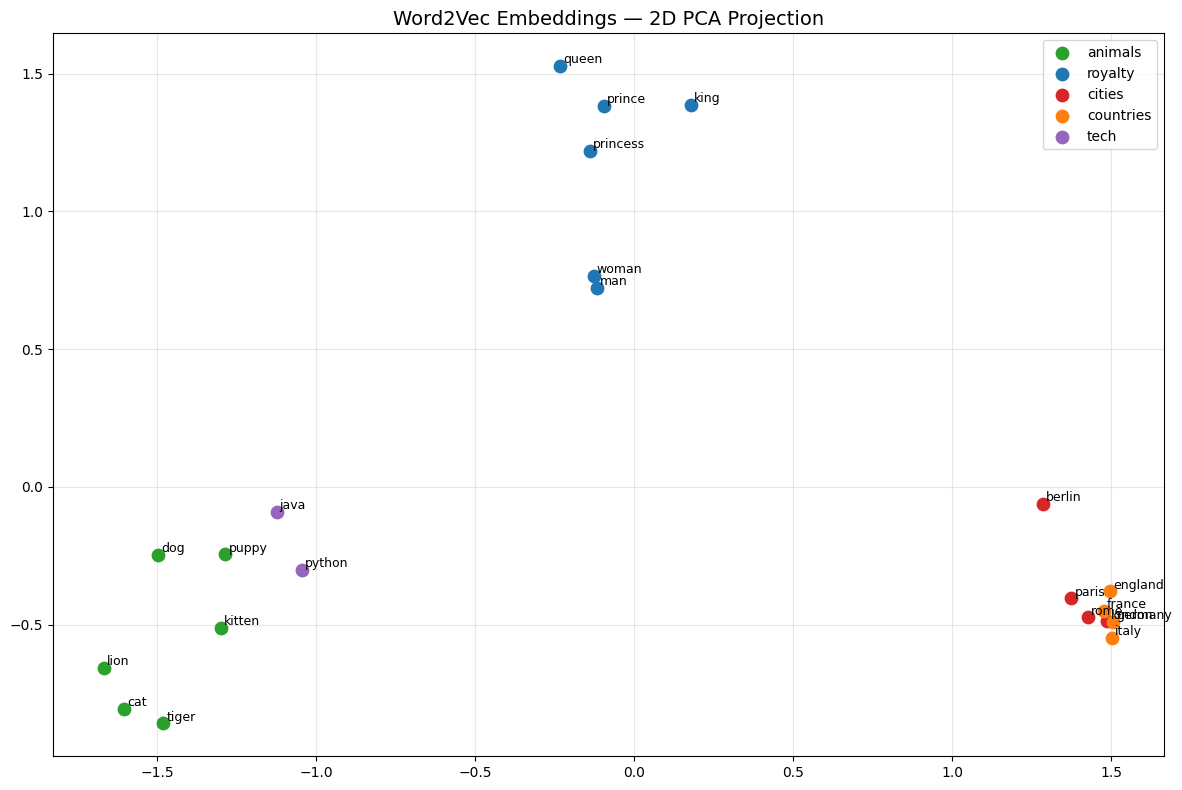


Explained variance ratio: [0.5051893  0.19643632]
Note: only 2 dimensions out of 50 are shown — some structure is lost!


In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

words_to_plot = [
    "cat", "dog", "lion", "tiger", "kitten", "puppy",
    "king", "queen", "prince", "princess", "man", "woman",
    "paris", "berlin", "london", "rome",
    "france", "germany", "england", "italy",
    "python", "java",
]
words_to_plot = [w for w in words_to_plot if w in model.wv]

vecs = np.array([model.wv[w] for w in words_to_plot])

pca  = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(vecs)

# Colour groups
groups = {
    "animals":    ["cat", "dog", "lion", "tiger", "kitten", "puppy"],
    "royalty":    ["king", "queen", "prince", "princess", "man", "woman"],
    "cities":     ["paris", "berlin", "london", "rome"],
    "countries":  ["france", "germany", "england", "italy"],
    "tech":       ["python", "java"],
}
color_map = {"animals": "tab:green", "royalty": "tab:blue",
             "cities": "tab:red",    "countries": "tab:orange", "tech": "tab:purple"}

fig, ax = plt.subplots(figsize=(12, 8))
for grp, members in groups.items():
    idxs = [words_to_plot.index(w) for w in members if w in words_to_plot]
    ax.scatter(coords[idxs, 0], coords[idxs, 1],
               c=color_map[grp], label=grp, s=80, zorder=3)

for i, word in enumerate(words_to_plot):
    ax.annotate(word, (coords[i, 0] + 0.01, coords[i, 1] + 0.01), fontsize=9)

ax.set_title("Word2Vec Embeddings — 2D PCA Projection", fontsize=14)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nExplained variance ratio: {pca.explained_variance_ratio_}")
print("Note: only 2 dimensions out of 50 are shown — some structure is lost!")


### Exercise 3b

Break it! Take a pair of words with high cosine similarity. Now modify the corpus (remove sentences or add misleading ones) until their similarity drops significantly.

In [ ]:
# Space for code or notes
pairs = [
    ("paris","berlin"),
]

print(f"{'Word 1':<12} {'Word 2':<12} {'Cosine Sim':>12}")
print("-" * 38)
for w1, w2 in pairs:
    sim = model.wv.similarity(w1, w2)
    print(f"{w1:<12} {w2:<12} {sim:>12.4f}")

Word 1       Word 2         Cosine Sim
--------------------------------------
paris        berlin             0.8704
